# Splitting a budget: welfare objectives and Lorenz floors

A program has a fixed budget to split among $n$ recipients, say households applying for heating assistance or school districts applying for grants. A dollar does more for some recipients than for others: here recipient $i$ needs $c_i$ dollars for one unit of benefit, so a recipient given $x_i$ dollars receives benefit $u_i = x_i / c_i$.

Maximizing total benefit gives the whole budget to the recipient with the smallest $c_i$. Every other objective in this notebook gives up some total benefit so that the recipients who get the least get more. We solve the same allocation five ways:

1. total benefit, $\sum_i u_i$ (a linear program),
2. Nash welfare, the geometric mean of the $u_i$, with `cp.geo_mean`,
3. power-mean welfare with $p < 1$, with `cp.pnorm(u, p)`,
4. generalized Gini welfare, a weighted sum of the sorted benefits that puts the most weight on the smallest, with `cp.dotsort`,
5. total benefit subject to Lorenz floors, which guarantee the $k$ worst-off recipients at least a stated total benefit for every $k$, with `cp.sum_smallest`.

The data are synthetic, and benefit is linear in dollars: there are no diminishing returns within a recipient. All five problems are DCP, and the default solver handles them.

In [1]:
import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np

## Data

Forty recipients share a budget of 100. The cost of one unit of benefit is drawn uniformly between 1 and 5.

If every recipient gets the same benefit $\bar u$, the budget is spent when $\bar u \sum_i c_i = 100$. We use this equal-benefit level $\bar u$ to set the Lorenz floors below.

In [2]:
rng = np.random.default_rng(0)
n, budget = 40, 100.0
cost = rng.uniform(1, 5, n)        # dollars per unit of benefit, by recipient
u_equal = budget / cost.sum()      # benefit per recipient if benefits are equal

print(f"cost per unit of benefit: {cost.min():.2f} to {cost.max():.2f}")
print(f"equal-benefit level: {u_equal:.4f} per recipient")

cost per unit of benefit: 1.01 to 4.99
equal-benefit level: 0.7945 per recipient


## Measuring inequality with `dotsort`

`cp.dotsort(u, w)` is the inner product of $u$ and $w$ after both are sorted. With weights $w_k = 2k - n - 1$ it equals the sum of $|u_i - u_j|$ over all pairs $i < j$, so the Gini coefficient of a nonnegative vector is

$$G(u) = \frac{\operatorname{dotsort}(u,\, 2k - n - 1)}{n \sum_i u_i}.$$

The numerator is convex, so `dotsort` can also bound inequality inside a problem. Here we only use it to evaluate solutions, and check it against the pairwise definition.

In [3]:
gini_weights = 2 * np.arange(1, n + 1) - n - 1

def gini(values):
    pair_sum = cp.dotsort(values, gini_weights).value
    return pair_sum / (n * values.sum())

v = rng.uniform(0, 1, n)
pairwise = np.abs(v[:, None] - v[None, :]).sum() / (2 * n * v.sum())
print(f"dotsort Gini {gini(v):.12f}, pairwise Gini {pairwise:.12f}")

dotsort Gini 0.335040705696, pairwise Gini 0.335040705696


## Five allocations

Each call to `allocate` builds a new problem on a new variable, with the budget constraint and any extra constraints, and returns the benefits.

The generalized Gini welfare is $\sum_k w_k u_{[k]}$, where $u_{[1]} \le \dots \le u_{[n]}$ are the sorted benefits and the weights decrease, here $w = (n, n-1, \dots, 1)$. `dotsort` sorts both arguments the same way, so we write it as `-cp.dotsort(-u, w)`, which is concave.

The Lorenz floors require `cp.sum_smallest(u, k) >= floor[k]` for $k = 1, \dots, n$. We set each floor to half of what the $k$ worst-off recipients would get if benefits were equal, $0.5\, k \bar u$, and maximize total benefit subject to them.

In [4]:
def allocate(objective, floors=None):
    """Maximize objective(u) subject to the budget and optional Lorenz floors."""
    x = cp.Variable(n, nonneg=True)    # dollars allocated
    u = cp.multiply(1 / cost, x)       # benefit received
    constraints = [cp.sum(x) <= budget]
    if floors is not None:
        constraints += [cp.sum_smallest(u, k) >= floors[k - 1] for k in range(1, n + 1)]
    problem = cp.Problem(cp.Maximize(objective(u)), constraints)
    problem.solve()
    return problem.status, (None if u.value is None else u.value)


def lorenz_floors(level):
    """Floors at `level` times the equal-benefit totals."""
    return level * u_equal * np.arange(1, n + 1)


ggw_weights = np.arange(n, 0, -1)
objectives = {
    "total benefit": (lambda u: cp.sum(u), None),
    "Nash welfare": (lambda u: cp.geo_mean(u, approx=False), None),
    "power mean, p = 0.5": (lambda u: cp.pnorm(u, 0.5), None),
    "generalized Gini welfare": (lambda u: -cp.dotsort(-u, ggw_weights), None),
    "Lorenz floors at 0.5": (lambda u: cp.sum(u), lorenz_floors(0.5)),
}

results = {}
print(f"{'objective':26s} {'status':8s} {'total':>7s} {'min':>6s} {'Gini':>6s}")
for name, (objective, floors) in objectives.items():
    status, u_val = allocate(objective, floors)
    results[name] = u_val
    print(f"{name:26s} {status:8s} {u_val.sum():7.2f} {u_val.min():6.3f} {gini(u_val):6.3f}")

objective                  status     total    min   Gini
total benefit              optimal    98.92  0.000  0.975
Nash welfare               optimal    39.72  0.501  0.284
power mean, p = 0.5        optimal    52.61  0.253  0.551
generalized Gini welfare   optimal    31.78  0.794  0.000


Lorenz floors at 0.5       optimal    65.35  0.397  0.738


Each objective has a simple reading in this model.

- **Total benefit** gives everything to the cheapest recipient, so 39 of the 40 get nothing.
- **Nash welfare** gives every recipient the same number of dollars, $x_i = 100/n$. Maximizing $\sum_i \log(x_i / c_i)$ is the same as maximizing $\sum_i \log x_i$, because the $c_i$ only add a constant.
- **Power-mean welfare** with exponent $p$ gives $x_i \propto c_i^{-p/(1-p)}$, from the optimality conditions. For $p = 0.5$ that is $x_i \propto 1/c_i$, so cheaper recipients get more dollars. As $p$ falls below 0 the allocation moves toward equal benefits.
- **Generalized Gini welfare** with these steep weights gives every recipient the same benefit $\bar u$. The objective is piecewise linear, so its solution jumps between corners rather than moving smoothly; flatter weights are shown below.
- **Lorenz floors** spend what the floors require on the worst-off recipients and send the rest of the budget to the cheapest.

The next cell checks the first three readings against the solver's allocations, in dollars.

In [5]:
dollars = {name: u_val * cost for name, u_val in results.items()}

print("Nash: largest gap from 100/n dollars",
      f"{np.abs(dollars['Nash welfare'] - budget / n).max():.1e}")
p = 0.5
closed_form = cost ** (-p / (1 - p))
closed_form *= budget / closed_form.sum()
print("power mean: largest gap from the closed form",
      f"{np.abs(dollars['power mean, p = 0.5'] - closed_form).max():.1e}")
print("generalized Gini: largest gap from equal benefits",
      f"{np.abs(results['generalized Gini welfare'] - u_equal).max():.1e}")

Nash: largest gap from 100/n dollars 1.9e-06
power mean: largest gap from the closed form 1.8e-03
generalized Gini: largest gap from equal benefits 8.7e-10


## Lorenz curves

The left panel shows generalized Lorenz curves: the total benefit of the $k$ worst-off recipients, against $k$. One allocation is at least as good as another for every $k$ exactly when its curve is never below the other's, and the Lorenz floors are a lower bound on this curve, drawn as a dashed line. The right panel shows ordinary Lorenz curves, the same totals as shares of each allocation's own total, which compare inequality without regard to how much benefit there is.

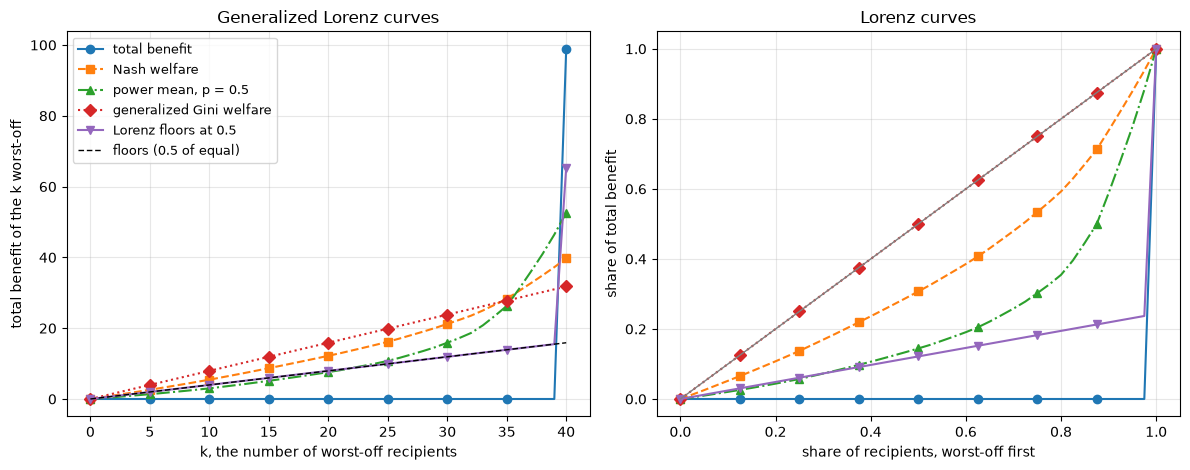

In [6]:
styles = {
    "total benefit": dict(color="C0", linestyle="-", marker="o"),
    "Nash welfare": dict(color="C1", linestyle="--", marker="s"),
    "power mean, p = 0.5": dict(color="C2", linestyle="-.", marker="^"),
    "generalized Gini welfare": dict(color="C3", linestyle=":", marker="D"),
    "Lorenz floors at 0.5": dict(color="C4", linestyle="-", marker="v"),
}
k = np.arange(0, n + 1)
fig, (ax_abs, ax_share) = plt.subplots(1, 2, figsize=(12, 4.8))
for name, u_val in results.items():
    cumulative = np.concatenate([[0], np.cumsum(np.sort(u_val))])
    ax_abs.plot(k, cumulative, markevery=5, label=name, **styles[name])
    ax_share.plot(k / n, cumulative / cumulative[-1], markevery=5, label=name, **styles[name])
ax_abs.plot(k, np.concatenate([[0], lorenz_floors(0.5)]), color="black", linestyle=(0, (4, 2)),
            linewidth=1, label="floors (0.5 of equal)")
ax_share.plot([0, 1], [0, 1], color="gray", linewidth=1, label="equal shares")
ax_abs.set(xlabel="k, the number of worst-off recipients",
           ylabel="total benefit of the k worst-off", title="Generalized Lorenz curves")
ax_share.set(xlabel="share of recipients, worst-off first",
             ylabel="share of total benefit", title="Lorenz curves")
for ax in (ax_abs, ax_share):
    ax.grid(alpha=0.3)
ax_abs.legend(fontsize=9)
fig.tight_layout()
plt.show()

In the left panel, the total-benefit curve stays at zero until the last recipient and then jumps to 98.9. The generalized Gini curve is a straight line, since everyone gets the same benefit, and it lies on or above every other curve for the worst-off 34 recipients. The Lorenz-floor curve follows the dashed floor line exactly until the last recipient, then jumps, because the floors are met with nothing to spare and the remaining budget goes to the cheapest recipient. In the right panel, the generalized Gini curve lies on the line of equal shares and the total-benefit curve lies along the bottom axis.

## How much total benefit equity costs

Raising the floor level from 0 to 1 traces how much total benefit is given up to raise the smallest benefit, and so does lowering the power-mean exponent $p$. A floor level of 1 forces every benefit up to $\bar u$, which spends the whole budget. Exponents below 0 use `cp.pnorm(u, p)` with negative $p$, which is also concave.

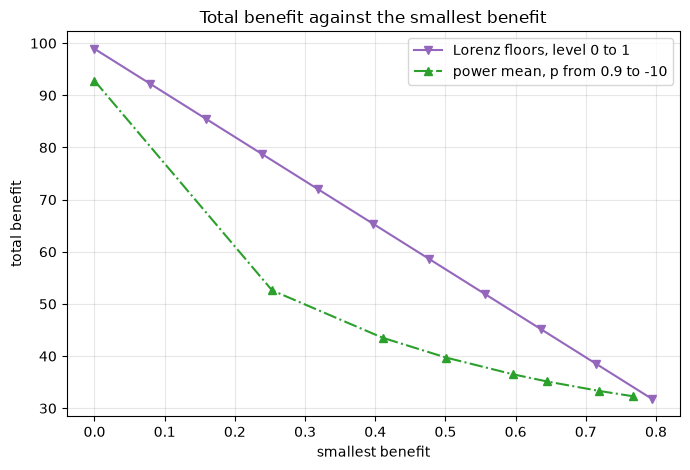

floor level 0.0: smallest 0.000, total  98.92
floor level 0.1: smallest 0.079, total  92.20
floor level 0.2: smallest 0.159, total  85.49
floor level 0.3: smallest 0.238, total  78.78
floor level 0.4: smallest 0.318, total  72.06
floor level 0.5: smallest 0.397, total  65.35
floor level 0.6: smallest 0.477, total  58.63
floor level 0.7: smallest 0.556, total  51.92
floor level 0.8: smallest 0.636, total  45.21
floor level 0.9: smallest 0.715, total  38.49
floor level 1.0: smallest 0.794, total  31.78


In [7]:
levels = np.linspace(0, 1, 11)
floor_points = []
for level in levels:
    _, u_val = allocate(lambda u: cp.sum(u), lorenz_floors(level))
    floor_points.append((u_val.min(), u_val.sum()))

exponents = [0.9, 0.5, 0.25, -0.5, -1, -3, -10]
power_points = []
for p in exponents:
    _, u_val = allocate(lambda u, p=p: cp.pnorm(u, p))
    power_points.append((u_val.min(), u_val.sum()))
power_points.insert(3, (results["Nash welfare"].min(), results["Nash welfare"].sum()))  # p -> 0

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(*zip(*floor_points), color="C4", marker="v", label="Lorenz floors, level 0 to 1")
ax.plot(*zip(*power_points), color="C2", linestyle="-.", marker="^",
        label="power mean, p from 0.9 to -10")
ax.set(xlabel="smallest benefit", ylabel="total benefit",
       title="Total benefit against the smallest benefit")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

for level, (low, total) in zip(levels, floor_points):
    print(f"floor level {level:.1f}: smallest {low:.3f}, total {total:6.2f}")

The floor solutions lie on a straight line from (0, 98.9) at level 0 to $(\bar u, 31.8)$ at level 1: each unit of benefit guaranteed to every recipient costs the same amount of total benefit. The power-mean solutions lie below that line: for the same smallest benefit they reach less total benefit. A floor solution holds the worst-off recipients exactly at their floors and gives everything else to the cheapest recipient, while a power mean spreads benefit across everyone above the minimum. So the floors are the cheaper way to guarantee a minimum, and the power means are the way to raise benefits across the whole distribution. Both families end at the equal-benefit allocation.

## Flatter generalized Gini weights

The weights $w = (n, \dots, 1)$ are steep enough that the optimum gives everyone the same benefit. Adding a constant $c$ to every weight puts more weight on total benefit. Because the objective is piecewise linear, the solution moves in jumps: here it stays at equal benefits up to an offset of 6 and jumps to an allocation that gives most recipients nothing by 6.5.

In [8]:
print(f"{'weight offset':>13s} {'total':>7s} {'min':>6s} {'Gini':>6s}")
for offset in [0, 2, 4, 6, 6.5, 8]:
    weights = offset + ggw_weights
    _, u_val = allocate(lambda u, w=weights: -cp.dotsort(-u, w))
    print(f"{offset:13g} {u_val.sum():7.2f} {u_val.min():6.3f} {gini(u_val):6.3f}")

weight offset   total    min   Gini
            0   31.78  0.794  0.000
            2   31.78  0.794  0.000
            4   31.78  0.794  0.000
            6   31.78  0.794  0.000
          6.5   91.10  0.000  0.875
            8   91.10  0.000  0.875


## When the floors cost more than the budget

Meeting the floor for $k = 1$ alone means giving every recipient at least the floor level times $\bar u$, which costs the floor level times the budget. Any level above 1 is therefore infeasible, and CVXPY reports it as such rather than returning an allocation.

In [9]:
status, u_val = allocate(lambda u: cp.sum(u), lorenz_floors(1.2))
print("floor level 1.2:", status)

floor level 1.2: infeasible


## Next steps

With real data, the cost per unit of benefit would come from program records, and benefit would usually have diminishing returns, $u_i = f_i(x_i)$ with each $f_i$ concave. All five objectives stay DCP after that change, since each is concave and nondecreasing in $u$. Constraints such as a per-recipient cap $x_i \le \text{cap}$ or a floor on dollars by region are added the same way as the budget.